In [5]:
# -----------------------------------------------
# ESTE EJERCICIO SE ENFOCA A VALIDAR EL DATASET
# Y HACER UN POCO DE ANALISIS DE DATOS
# 
# ------------------------------------------------



#importamos la libreria y cargamos el archivo
import pandas as pd
datos = pd.read_csv("U4_01_housing.csv")

! ANALIZMOS EL DATASET !
Este apartado veremos como analizar el DataSet que nos llega para poder limpiarlo y tener datos sólidos para meterlo a un modelo y entrenarlo.

In [6]:
#vista previa de los datos
datos.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [7]:
#Vemos los tipos de datos , columnas que tiene el DataSet
# ya que Machine Learning trabaja con datos numericos
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


En la info() podemos ver lo siguiente:
1.- Todos son flotantes menos "ocean_proximity" : TENEMOS QUE ARREGARLO
1.- Todos los campos tienen 20640 Registros excepto "total_bedrooms" con 20433 es decir tiene al rededor de 200 Datos vacios con NA : TENEMOS QUE ARREGARLO

In [8]:
# Ya que la columna "ocean_promitiy" no es numerico. 
# Verificamos que informacion trae esta columna para poder TRANSFORMARLA
# para esto usamos la funcion value_counts() funciona como un DISTINCT
# Nos dice los que hay de forma unica y cuanto hay
#
datos["ocean_proximity"].value_counts()


ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

In [9]:
# Exploramos datos interesantes Del DataSet
#La función describe() en Python, cuando se aplica a un conjunto de datos (por ejemplo, un DataFrame de pandas), proporciona un resumen estadístico de las columnas numéricas. Los valores que devuelve son los siguientes:
# count: El número de elementos no nulos en la columna. Este valor indica cuántas observaciones hay en la muestra.
# mean: La media aritmética de los valores en la columna. Se calcula sumando todos los valores y dividiendo por el número de elementos.
# std: La desviación estándar de los valores en la columna. La desviación estándar es una medida de dispersión que indica cuánto varían los valores de la media.
# min: El valor mínimo en la columna, es decir, el valor más pequeño.
# 25%: El percentil 25, también conocido como el primer cuartil o Q1. Indica el valor por debajo del cual se encuentra el 25% de los datos.
# 50%: El percentil 50, que es la mediana. Indica el valor que separa la mitad superior de la mitad inferior de los datos cuando están ordenados de menor a mayor.
# 75%: El percentil 75, también conocido como el tercer cuartil o Q3. Indica el valor por debajo del cual se encuentra el 75% de los datos.
# max: El valor máximo en la columna, es decir, el valor más grande.
datos.describe()


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value
count,20640.000000,20640.000000,20640.000000,20640.000000,20433.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,-119.569704,35.631861,28.639486,2635.763081,537.870553,1425.476744,499.539680,3.870671,206855.816909
std,2.003532,2.135952,12.585558,2181.615252,421.385070,1132.462122,382.329753,1.899822,115395.615874
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000
25%,-121.800000,33.930000,18.000000,1447.750000,296.000000,787.000000,280.000000,2.563400,119600.000000
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.534800,179700.000000
75%,-118.010000,37.710000,37.000000,3148.000000,647.000000,1725.000000,605.000000,4.743250,264725.000000
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000


array([[<Axes: title={'center': 'longitude'}>,
        <Axes: title={'center': 'latitude'}>,
        <Axes: title={'center': 'housing_median_age'}>],
       [<Axes: title={'center': 'total_rooms'}>,
        <Axes: title={'center': 'total_bedrooms'}>,
        <Axes: title={'center': 'population'}>],
       [<Axes: title={'center': 'households'}>,
        <Axes: title={'center': 'median_income'}>,
        <Axes: title={'center': 'median_house_value'}>]], dtype=object)

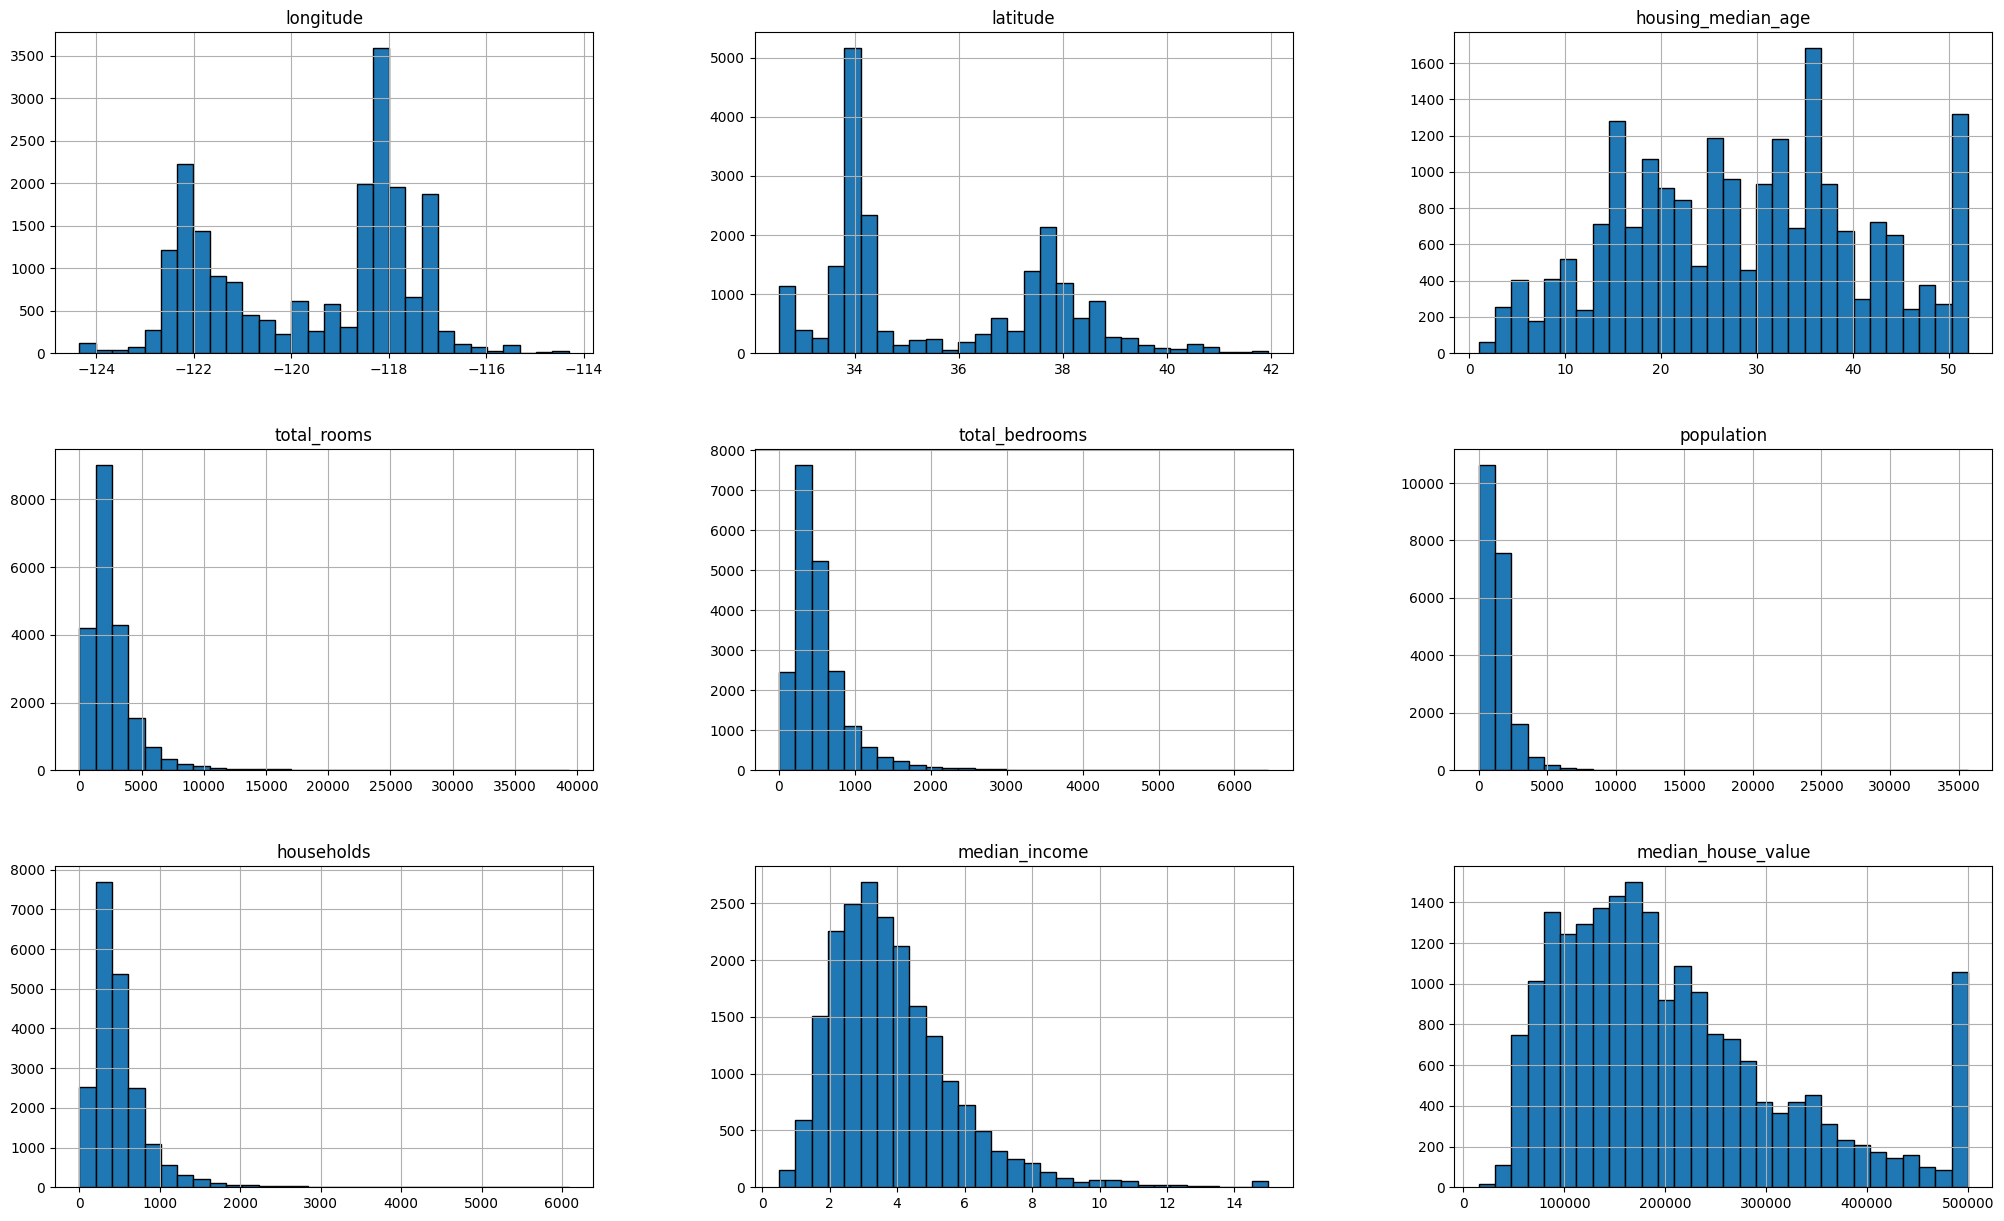

In [10]:
#Ploteamos graficas para poder comprender mejor los datos
datos.hist(figsize=[25,15], bins=30, edgecolor="black")

En los datos de las graficas de datos.hist() podemos ver lo siguiente:
1.- Los datos de cada grafica nos indican si estan cargadas en el centro , izquierda o derecha segun el "campo" lo que indique. Sin embargo lo que se puede analizar de forma interesante son los campos de "Latitud y Longitud" como sigue.

TypeError: cannot convert the series to <class 'float'>

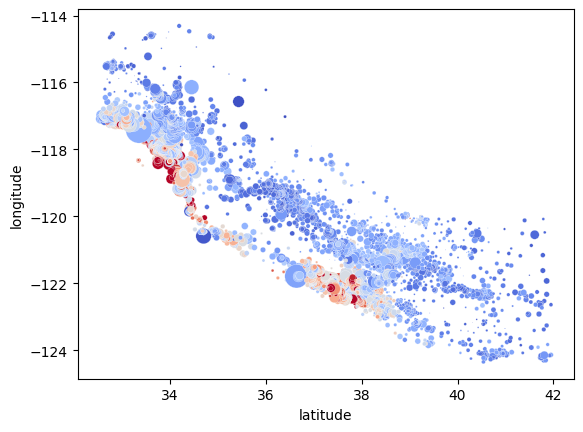

In [11]:
# Ploteamos los datos Longitud y Latitud
# Convertir la serie a float de manera segura

def safe_convert_to_float(x):
    try:
        return float(x)
    except (TypeError, ValueError):
        return float('nan')  # Si no se puede convertir, devolver NaN

# Aplicar la función safe_convert_to_float a la serie "population"
#datos["population"] = datos["population"].apply(safe_convert_to_float)


import seaborn as sb
sb.scatterplot(x="latitude",y="longitude", data=datos,
               hue="median_house_value", # Hacemos que el color dependa del precio de la casa
               palette="coolwarm", #Cambiamos el color de la paleta de colores para ver las casas mas detectables
                                  #NOTA: con esto podemos ver que lsa casas mas caras estan cerca del oceano
               s=datos["population"]/100 #Hacemos que el tamaño de los circulos dependa del tamaño de la poblacion
               )

NOTA: Al parecer esta grafica no tiene mucho sentido pero si lo comparamos con el mapa de california, se encuentra todo el sentido. (Ver imagen de Mapa de California)
![image.png](attachment:MapaCalifornia.png)


<Axes: xlabel='latitude', ylabel='longitude'>

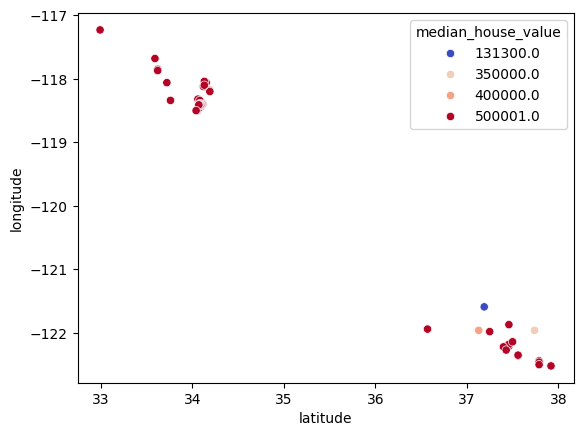

In [12]:
# Ploteamos los datos Longitud y Latitud Con la gente que gana MAS
# Convertir la serie a float de manera segura

import seaborn as sb
sb.scatterplot(x="latitude",y="longitude", 
               data=datos[datos.median_income > 14], # Con esto filtramos el campo "median_income" para ver las personas que ganas mas.
               hue="median_house_value", # Hacemos que el color dependa del precio de la casa
               palette="coolwarm" #Cambiamos el color de la paleta de colores para ver las casas mas detectables
                                  #NOTA: con esto podemos ver que lsa casas mas caras estan cerca del oceano
               #s=datos["population"]/100 #Hacemos que el tamaño de los circulos dependa del tamaño de la poblacion
               )


#-
HASTA AQUI VIMOS ALGUNAS FUNCIONES PARA ANALIZAR LA DATA
AHORA VAMOS A LIMPIAR EL SET DE DATOS 


En la info() podemos ver lo siguiente:
1.- Todos son flotantes menos "ocean_proximity" : TENEMOS QUE ARREGARLO
1.- Todos los campos tienen 20640 Registros excepto "total_bedrooms" con 20433 es decir tiene al rededor de 200 Datos vacios con NA : TENEMOS QUE ARREGARLO

In [13]:
datos.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.6+ MB


In [14]:
# 1. LIMPIAMOS TODOS LOS DATOS ELIMINANDO LOS QUE TIENEN "NA" o SON NULOS
datos_na = datos.dropna()

In [15]:
# Comprobamos que todos tengan la misma cantidad de registros.
datos_na.info()

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   ocean_proximity     20433 non-null  object 
dtypes: float64(9), object(1)
memory usage: 1.7+ MB


In [27]:
#2.- LIMPIAMOS EL OBJETO ocena_proximity CON LOS SIGUIENTES VALORES
# EN FORMATO Dommies / One-Hot Encodig

#ocean_proximity
#<1H OCEAN     9136
#INLAND        6551
#NEAR OCEAN    2658
#NEAR BAY      2290
#ISLAND           5
#Name: count, dtype: int64

# Formato Dommies / One-Hot Encodig : transforma la informacion en matriz i.e:
# INLAND        NEAR OCEAN          NEAR BAY
#   1               0                   0
#   0               1                   0

ocean_proximity_dummies = pd.get_dummies(datos_na["ocean_proximity"], 
               dtype=int    # Forzamos que nos de los datos en enteros y no en TRUE/FALSE
               )
#podemos ver los resultados.
#ocean_proximity_dummies.head()
#ocean_proximity_dummies.info()

In [29]:
#2.1  Agregamos los dumies de "ocean_proximity" al dataset de datos_na
datos_na = datos_na.join(ocean_proximity_dummies)

In [30]:
#2.2 Confirmamos que los dummies hayan sido agregados
datos_na.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY,0,0,0,1,0


In [32]:
#2.3 Quitamos la columna de "ocean_proximity" ya que no se necesita
datos_na = datos_na.drop(["ocean_proximity"], 
              axis=1    #Determinamos que "ocean_proximity" es una columna poniendo "axis=1"
            )

In [33]:
#2.4 Confirmamos como quedaron nuestros datos.
datos_na.head() 

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,0,0,0,1,0
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,0,0,0,1,0
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,0,0,0,1,0
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,0,0,0,1,0
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,0,0,0,1,0


#-
SEGUIREMOS CON LAS CORRELACIONES


In [35]:
# ----- CORRELACIONES ---- 
#3. Ver las correlaciones entre todas las columnas. 

datos_na.corr()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN
longitude,1.000000,-0.924616,-0.109357,0.045480,0.069608,0.100270,0.056513,-0.015550,-0.045398,0.320831,-0.055337,0.009501,-0.474714,0.046185
latitude,-0.924616,1.000000,0.011899,-0.036667,-0.066983,-0.108997,-0.071774,-0.079626,-0.144638,-0.446928,0.351084,-0.016662,0.358785,-0.161342
housing_median_age,-0.109357,0.011899,1.000000,-0.360628,-0.320451,-0.295787,-0.302768,-0.118278,0.106432,0.045553,-0.236968,0.017105,0.256149,0.020797
total_rooms,0.045480,-0.036667,-0.360628,1.000000,0.930380,0.857281,0.918992,0.197882,0.133294,-0.003777,0.026477,-0.007603,-0.023647,-0.008674
total_bedrooms,0.069608,-0.066983,-0.320451,0.930380,1.000000,0.877747,0.979728,-0.007723,0.049686,0.018314,-0.006463,-0.004361,-0.019873,0.000679
population,0.100270,-0.108997,-0.295787,0.857281,0.877747,1.000000,0.907186,0.005087,-0.025300,0.073450,-0.019602,-0.010451,-0.061480,-0.023498
households,0.056513,-0.071774,-0.302768,0.918992,0.979728,0.907186,1.000000,0.013434,0.064894,0.041883,-0.038265,-0.009119,-0.011280,0.002106
median_income,-0.015550,-0.079626,-0.118278,0.197882,-0.007723,0.005087,0.013434,1.000000,0.688355,0.168715,-0.237536,-0.009281,0.056677,0.027351
median_house_value,-0.045398,-0.144638,0.106432,0.133294,0.049686,-0.025300,0.064894,0.688355,1.000000,0.257614,-0.484787,0.023525,0.160526,0.140378
<1H OCEAN,0.320831,-0.446928,0.045553,-0.003777,0.018314,0.073450,0.041883,0.168715,0.257614,1.000000,-0.607778,-0.013928,-0.314721,-0.342018


<Axes: >

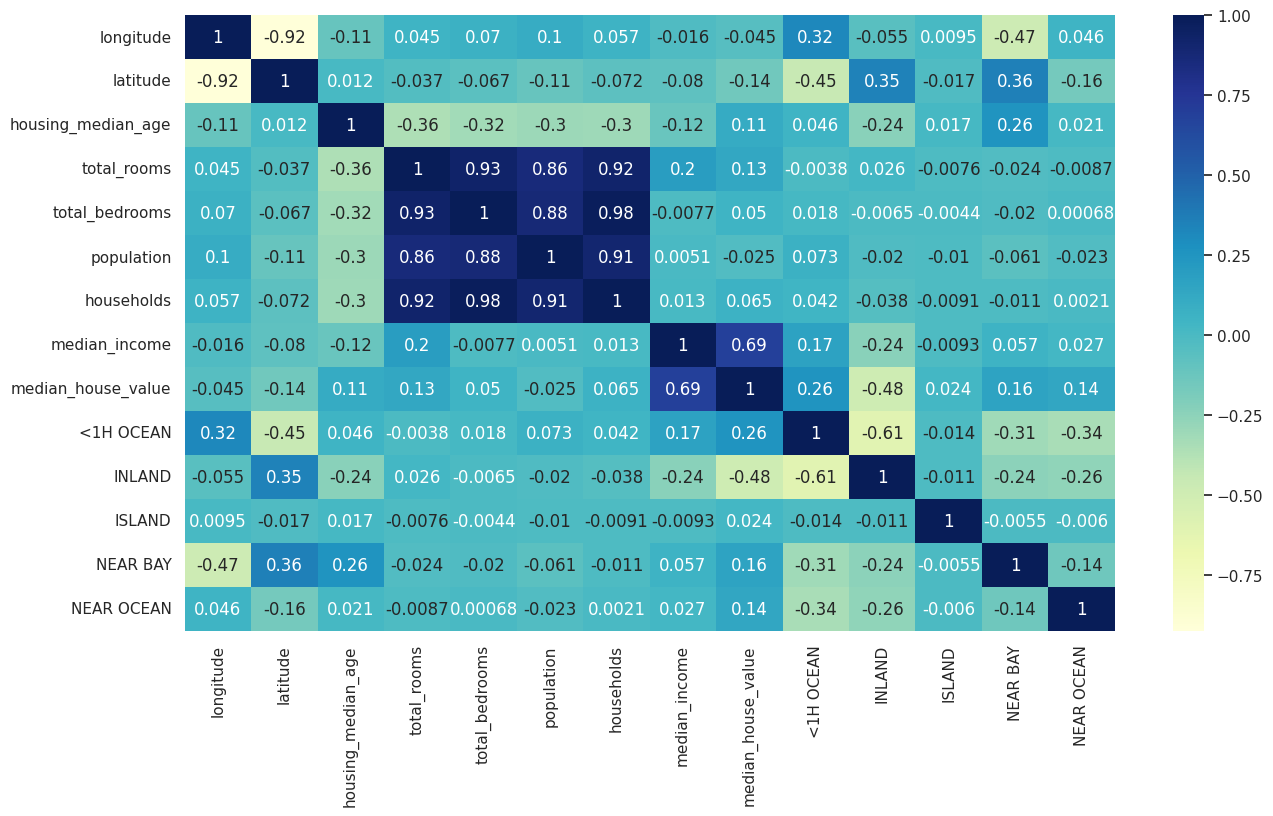

In [53]:
# 3.1 Ploteamos las correlaciones
sb.set(rc={'figure.figsize':(15,8)})
sb.heatmap(datos_na.corr(),
           annot=True, # Mostramos los valores de las correlaciones
            cmap="YlGnBu",
            #annot_kws={"weight": "bold", "color": "black"} # Configurar el texto de las anotaciones en negritas
           )
# Obtener el objeto de los ejes y cambiar el tamaño de las etiquetas


In [54]:
# 3.2 Obtener la correlacion unicamente de la columna que nos interesa.
# en este caso el precio de la casa. 
datos_na.corr()["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688355
<1H OCEAN             0.257614
NEAR BAY              0.160526
NEAR OCEAN            0.140378
total_rooms           0.133294
housing_median_age    0.106432
households            0.064894
total_bedrooms        0.049686
ISLAND                0.023525
population           -0.025300
longitude            -0.045398
latitude             -0.144638
INLAND               -0.484787
Name: median_house_value, dtype: float64

#-
HASTA AQUI VIMOS ALGUNAS FUNCIONES PARA ANALIZAR LA DATA
AHORA VAMOS A REALIZAR EL MODELO DE REGRESION LINEAL


REGRESION LINEAL


<Axes: xlabel='median_house_value', ylabel='median_income'>

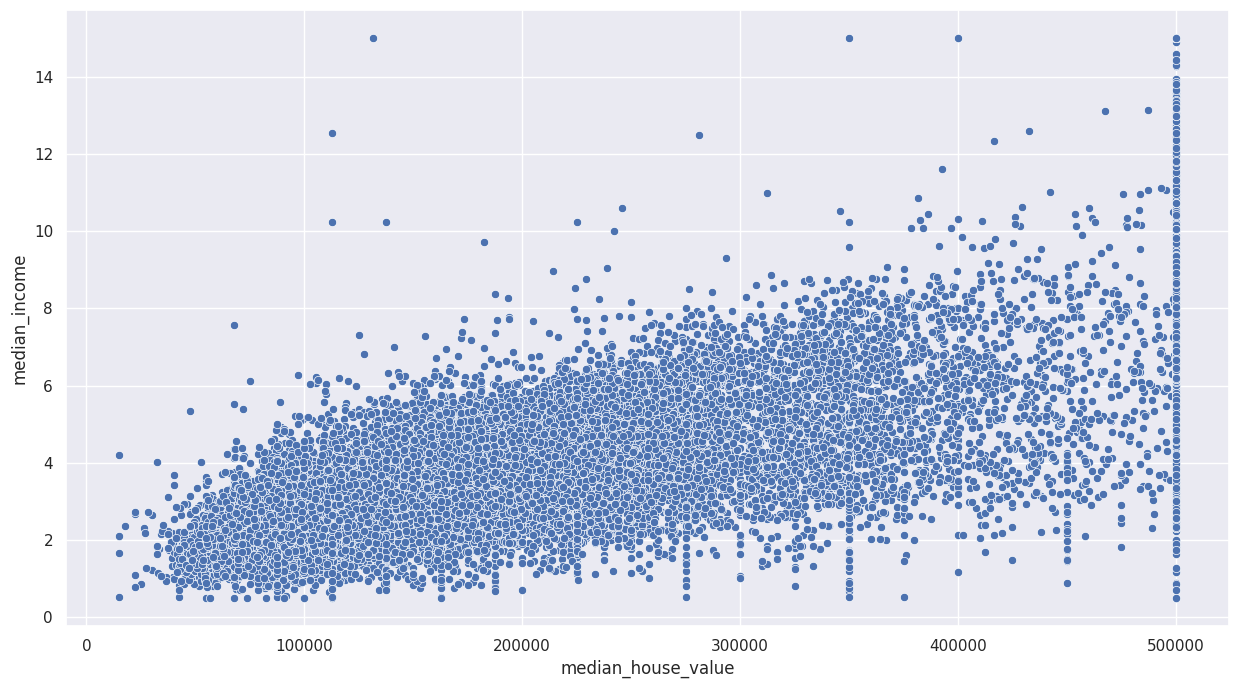

In [56]:
#1.- Visualizamos de forma grafica los precios de la casa 
sb.scatterplot(x=datos_na['median_house_value'], y=datos_na['median_income'])

# Con esta grafica podemos ver la media de ingresos y como estan distribuidos
# los ingresos y podemos ver como la regresion lineal nos pudiera ayudar. 
# ya que es ascendente. 

# 2. AGREGANDO CARACTERISTICAS AL DATA SET 


In [57]:
# 2. Agregemos una caracterisitca:
# Ver la relacion cuantos de los cuartos son cuartos para dormir
datos_na["bedroom_ratio"] = datos_na["total_bedrooms"] / datos_na['total_rooms']

<Axes: >

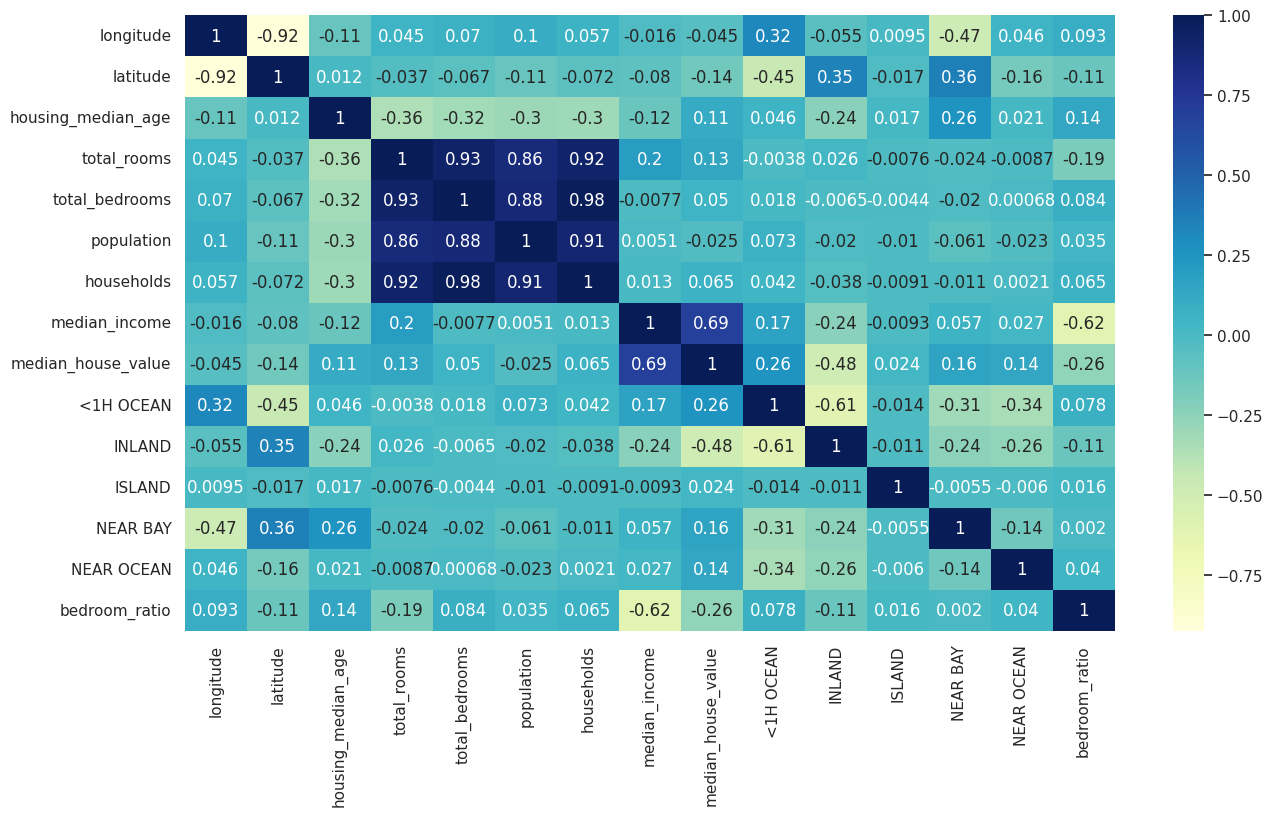

In [58]:
# 2.1 Volvemos a Plotear las correlaciones ya con la caracteristica agregada
# bedroom_ratio VS median_house_value

sb.set(rc={'figure.figsize':(15,8)})
sb.heatmap(datos_na.corr(),
           annot=True, # Mostramos los valores de las correlaciones
            cmap="YlGnBu",
            #annot_kws={"weight": "bold", "color": "black"} # Configurar el texto de las anotaciones en negritas
           )
# Obtener el objeto de los ejes y cambiar el tamaño de las etiquetas

In [62]:
# bedroom_ratio VS median_house_value vemos que tiene una correlacion 
#de -.26 es decir entre menos de los cuartos sean recamaras para dormir
#mas cuesta la casa

# Siguiente paso: Separar todas las caracteristicas y salidas para nuestro Modelo

In [63]:
# 2.2 Separamos las variales X y Y Caracteristicas y Salidas 
# imprimimos todas las caracteristicas  o columnas para ver las que queremos de salida
# en ste caso la respuesta o salida que queremos es "median_house_value"
datos_na.info()
 

<class 'pandas.core.frame.DataFrame'>
Index: 20433 entries, 0 to 20639
Data columns (total 15 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20433 non-null  float64
 1   latitude            20433 non-null  float64
 2   housing_median_age  20433 non-null  float64
 3   total_rooms         20433 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20433 non-null  float64
 6   households          20433 non-null  float64
 7   median_income       20433 non-null  float64
 8   median_house_value  20433 non-null  float64
 9   <1H OCEAN           20433 non-null  int64  
 10  INLAND              20433 non-null  int64  
 11  ISLAND              20433 non-null  int64  
 12  NEAR BAY            20433 non-null  int64  
 13  NEAR OCEAN          20433 non-null  int64  
 14  bedroom_ratio       20433 non-null  float64
dtypes: float64(10), int64(5)
memory usage: 2.5 MB


In [64]:
# 2.3 Separamos las caracteristicas de la etiquieta
X_Entradas = datos_na.drop(["median_house_value"], axis=1)
Y_Salidas = datos_na["median_house_value"]

In [72]:
# 2.4 Separamos los datos en 2 conjunto de datos o 2 partes
# Datos de entrenamiento 
# Datos de pruebas.

from sklearn.model_selection import train_test_split
X_Ent, X_Pru, Y_Ent, Y_Pru = train_test_split(X_Entradas,Y_Salidas, test_size=.2)

In [78]:
# 2.5 Validmos la cantidad de datos 
X_Ent.shape  # No muestran 16346 datos de entrenamiento (Entradas) con 2 columnas
Y_Ent.shape  # No muestran 16346 datos de entrenamiento (Salidas)
print( "Total de Datos de Entreamineto ")

Total de Datos de Entreamineto 


# 3. PREPARAMOS NUESTRO MODELO


In [79]:
# 3.1 Importamos e instanciamos el modelo de Regresion Lineal
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()

In [80]:
# 3.2 Entrenamos el Modelo 
modelo.fit(X_Ent,Y_Ent)

LinearRegression()

# 4. HACEMOS PREDICCIONES CON EL CONJUNTO DE PRUEBAS

In [82]:
# 4 Hacemos predicciones usando el conjunto de pruebas par aluego compararlas 
# con las salidas reales para ver que tan bien le fue 
predicciones = modelo.predict(X_Pru)

# 4.1 Lo ponemos en un dataFrame
pd.DataFrame(predicciones)

,0
0,74986.422712
1,486985.827239
2,254273.161045
3,230824.244327
4,235882.065883
...,...
4082,255478.344879
4083,255380.373732
4084,258483.551931
4085,122564.954767


In [84]:
# 4.2 Comparmos las predicciones que hizo con las reales. 
comparativa = {"Prediccion" : predicciones , "ValorReal" : Y_Pru}
pd.DataFrame(comparativa)

# Vemos como el dataFrame tiene 2 columnas con nombres "Prediccion" y "ValorReal"

# NOTA : Vemos como hay que prepocesar los datos ya que en elagunos casos esta 
# lejos y otros cerca.

,Prediccion,ValorReal
9260,74986.422712,65200.0
10999,486985.827239,487200.0
525,254273.161045,206300.0
8387,230824.244327,218800.0
17218,235882.065883,300000.0
...,...,...
10603,255478.344879,199600.0
770,255380.373732,200600.0
7675,258483.551931,167400.0
19371,122564.954767,208300.0


In [87]:
# 4.3 Validamos el Overfitting o Sobreajuste
# Visualizamos el score del modelo para saber que tan bien entreno. 
# Entre mas se acerce al 1 indica que esta muy bien entrenada.

print(modelo.score(X_Ent,Y_Ent))
print(modelo.score(X_Pru,Y_Pru))

# En estos 2 vemos que los puntajes son casi similares es decir no hay Sobreajuste
# 0.6551649500240905
# 0.6334532970946193

# En estos 2 

0.6551649500240905
0.6334532970946193


In [91]:
# 4.4 Validamos el ERROR para saber que tanto esta errando
# comparando lo real con las predicciones

from sklearn.metrics import mean_squared_error
import numpy as np

MSE = mean_squared_error(Y_Pru,predicciones) # Esta funcion nos da un valor grande
# Ya que los residuales los eleva al cuadrado 2 y los negativos se vuelvan positivos
# 4817680018.960723 est enumeo que nos devuelve lo podemos reducir para ser mas legible
# obteniendo su Raiz Cuadrada
print(MSE)

RaizCuadradaMSE = np.sqrt(MSE)
print(RaizCuadradaMSE)

# RaizCuadradaMSE : NOs muestra el prodemo del error que tenemos al calcular el precio
# de las casas. 
# Una de las razones es la desproporcion de los valores. es decir ejemplo
# en la Poblacion hay valores de 3 - 35K
# en la precio promedio "housing_median_age" valores de 1 - 52K
# etc.... 
# con esta dispersion de datos a los valores mas grande puede darle pesos mas grandes
# por ello la Finalidad es poder escalar los datos para que oscilen en un rango 


4817680018.960723
69409.50957153294


# 5. HACEMOS EL ESCALAMIENTO o SCALES DE LOS DATOS  

In [93]:
# 5.1 Vemos los datos para visualizar su desproporcion
datos_na.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,<1H OCEAN,INLAND,ISLAND,NEAR BAY,NEAR OCEAN,bedroom_ratio
count,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000,20433.000000
mean,-119.570689,35.633221,28.633094,2636.504233,537.870553,1424.946949,499.433465,3.871162,206864.413155,0.442128,0.317917,0.000245,0.111095,0.128615,0.213039
std,2.003578,2.136348,12.591805,2185.269567,421.385070,1133.208490,382.299226,1.899291,115435.667099,0.496652,0.465678,0.015641,0.314257,0.334782,0.057983
min,-124.350000,32.540000,1.000000,2.000000,1.000000,3.000000,1.000000,0.499900,14999.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.100000
25%,-121.800000,33.930000,18.000000,1450.000000,296.000000,787.000000,280.000000,2.563700,119500.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.175427
50%,-118.490000,34.260000,29.000000,2127.000000,435.000000,1166.000000,409.000000,3.536500,179700.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.203162
75%,-118.010000,37.720000,37.000000,3143.000000,647.000000,1722.000000,604.000000,4.744000,264700.000000,1.000000,1.000000,0.000000,0.000000,0.000000,0.239821
max,-114.310000,41.950000,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,15.000100,500001.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000


In [105]:
# 5.2 Escalamos los datos
# NOTA : Cuando escalamos los datos lo aplicamos a los datos de entrada
# los datos de pruebas, SOLO EN LOS DE PRUEBAS NO EN LOS DE SALIDA
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
X_Ent_Scaled = scaler.fit_transform(X_Ent)
X_Pru_Scaled = scaler.fit_transform(X_Pru)

# 5.3 Los ponemos en un dataFrame
pd.DataFrame(X_Ent_Scaled)
pd.DataFrame(X_Pru_Scaled)

# CON ESTOS DATOS PODEMOS REALIZAR EL ENTRAMIENTO. 
# Y VER LA GRAFICA DE CORRELACION PARA MEJORAR EL MODELO.

,0,1,2,3,4,5,6,7,8,9,10,11,12,13
0,-0.236321,0.589625,0.273204,-0.619038,-0.586755,-0.683987,-0.575844,-1.263902,-0.867943,1.430988,-0.015644,-0.348668,-0.392675,0.180632
1,0.896116,-0.886309,-0.287290,-0.266956,-0.658574,-0.490711,-0.637459,3.741181,1.152150,-0.698818,-0.015644,-0.348668,-0.392675,-1.540973
2,-1.314123,0.963221,1.874613,-0.416213,-0.348132,-0.421069,-0.319117,-0.122221,-0.867943,-0.698818,-0.015644,2.868054,-0.392675,0.222393
3,0.613007,-0.784838,0.833697,-0.827358,-0.813795,-0.844398,-0.881349,-0.152658,1.152150,-0.698818,-0.015644,-0.348668,-0.392675,0.256197
4,-0.052548,-0.577285,1.874613,-0.752271,-0.572855,-0.791188,-0.578411,-0.912684,1.152150,-0.698818,-0.015644,-0.348668,-0.392675,1.437418
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4082,0.886182,-0.927819,-1.568417,-0.482143,-0.549688,-0.585393,-0.521931,0.696385,1.152150,-0.698818,-0.015644,-0.348668,-0.392675,-0.379692
4083,-1.244588,0.912486,0.433344,-0.899239,-0.975966,-0.845963,-0.989175,0.422821,-0.867943,-0.698818,-0.015644,2.868054,-0.392675,-0.648046
4084,0.747111,-0.812512,0.593485,-0.811791,-0.813795,-0.555658,-0.778659,0.509701,1.152150,-0.698818,-0.015644,-0.348668,-0.392675,0.098110
4085,-0.618767,1.032406,-0.127149,-0.983940,-1.047784,-0.960989,-1.091866,-0.282951,-0.867943,1.430988,-0.015644,-0.348668,-0.392675,-0.595449


# 6. ENTRENAMOS EL MODELO CON LOS DATOS ESCALADOS

In [106]:
# 6. HACEMOS EL ESCALAMIENTO o SCALES DE LOS DATOS  
# 6.1 Entrenamos el Modelo 
modelo.fit(X_Ent_Scaled,Y_Ent)

LinearRegression()

In [107]:
# 6.2 Hacemos predicciones CON EL MODELO ESCALADO 
# usando el conjunto de pruebas par aluego compararlas 
# con las salidas reales para ver que tan bien le fue 
predicciones_escaladas = modelo.predict(X_Pru_Scaled)

# 4.1 Lo ponemos en un dataFrame
pd.DataFrame(predicciones_escaladas)

,0
0,73033.937062
1,480211.405623
2,253254.495836
3,225408.376023
4,231555.809924
...,...
4082,250668.711979
4083,250608.707237
4084,254839.767372
4085,118025.076111


In [108]:
# 6.2 Comparmos las predicciones que hizo con las reales. YA ESCALADOS LOS DATOS  
comparativa_escalada = {"Prediccion" : predicciones_escaladas , "ValorReal" : Y_Pru}
pd.DataFrame(comparativa_escalada)

# Vemos como el dataFrame tiene 2 columnas con nombres "Prediccion" y "ValorReal"

# NOTA : Vemos como hay que prepocesar los datos ya que en elagunos casos esta 
# lejos y otros cerca.

,Prediccion,ValorReal
9260,73033.937062,65200.0
10999,480211.405623,487200.0
525,253254.495836,206300.0
8387,225408.376023,218800.0
17218,231555.809924,300000.0
...,...,...
10603,250668.711979,199600.0
770,250608.707237,200600.0
7675,254839.767372,167400.0
19371,118025.076111,208300.0


In [109]:
# 6.3 Validamos el Overfitting o Sobreajuste DEL MODELO ESCALADO
# Visualizamos el score del modelo para saber que tan bien entreno. 
# Entre mas se acerce al 1 indica que esta muy bien entrenada.

print(modelo.score(X_Ent_Scaled,Y_Ent))
print(modelo.score(X_Pru_Scaled,Y_Pru))

# En estos 2 vemos que los puntajes son casi similares es decir no hay Sobreajuste
# 0.6551649500240905
# 0.6334532970946193

0.6551649500240904
0.6406097167511916


In [110]:
# 6.4 Validamos el ERROR DEL MODELO ESCALADO para saber que tanto esta errando
# comparando lo real con las predicciones


MSE = mean_squared_error(Y_Pru,predicciones_escaladas) # Esta funcion nos da un valor grande
# Ya que los residuales los eleva al cuadrado 2 y los negativos se vuelvan positivos
# 4817680018.960723 est enumeo que nos devuelve lo podemos reducir para ser mas legible
# obteniendo su Raiz Cuadrada
print(MSE)

RaizCuadradaMSE_escalado = np.sqrt(MSE)
print(RaizCuadradaMSE_escalado)

4723620135.967679
68728.59765750848
